# Workshop-3: Streaming ETL with Apache Kafka and Machine Learning
## Part A — Step 1: Exploratory Data Analysis (EDA)

### Objective
Perform a rigorous Exploratory Data Analysis (EDA) across the five historical World Happiness Report datasets (`2015.csv` through `2019.csv` located in `../data/raw/`) prior to data cleaning, schema harmonization, and machine learning pipeline construction.

Specifically, this notebook analyzes:
1. **Dataset Dimensions & Initial Overview** (`2015.csv` – `2019.csv`)
2. **Schema Differences & Inconsistent Column Names Across Years**
3. **Data Types & Entity Naming Inconsistencies (`Country` variations)**
4. **Missing Values (`NaN` / Null Analysis)**
5. **Duplicated Records Analysis (Full-row & Entity-level)**
6. **Descriptive Statistics, Zero-Value Baselines & Potential Outliers (IQR + Boxplots)**
7. **Comprehensive Data Quality Observations & Unified Analytical Schema Proposal**

---
## 1. Environment Setup and Raw Data Inspection
We begin by loading the five raw CSV files from `../data/raw/` without applying any premature transformations so we can inspect their native structure.

In [1]:
import sys
import asyncio
if sys.platform == "win32":
    try:
        asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())
    except Exception:
        pass

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual style and pandas display options
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

RAW_DATA_DIR = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")
YEARS = [2015, 2016, 2017, 2018, 2019]

raw_datasets = {}
overview_records = []

for year in YEARS:
    file_path = RAW_DATA_DIR / f"{year}.csv"
    df = pd.read_csv(file_path)
    raw_datasets[year] = df
    overview_records.append({
        "year": year,
        "file_name": file_path.name,
        "num_rows": df.shape[0],
        "num_columns": df.shape[1],
        "total_cells": df.size,
        "missing_cells": int(df.isna().sum().sum()),
        "exact_duplicate_rows": int(df.duplicated().sum())
    })

overview_df = pd.DataFrame(overview_records)
print(f"Total rows across all 5 datasets: {overview_df['num_rows'].sum()}")
overview_df

C:\Users\juand\AppData\Local\Temp\ipykernel_7992\3236240141.py:5: DeprecationWarning: 'asyncio.WindowsSelectorEventLoopPolicy' is deprecated and slated for removal in Python 3.16
  asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())
C:\Users\juand\AppData\Local\Temp\ipykernel_7992\3236240141.py:5: DeprecationWarning: 'asyncio.set_event_loop_policy' is deprecated and slated for removal in Python 3.16
  asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())


Total rows across all 5 datasets: 782


,year,file_name,num_rows,num_columns,total_cells,missing_cells,exact_duplicate_rows
0,2015,2015.csv,158,12,1896,0,0
1,2016,2016.csv,157,13,2041,0,0
2,2017,2017.csv,155,12,1860,0,0
3,2018,2018.csv,156,9,1404,1,0
4,2019,2019.csv,156,9,1404,0,0


In [2]:
# Preview the first 2 rows of each yearly dataset to observe structural differences
for year, df in raw_datasets.items():
    print(f"================ {year} (Shape: {df.shape}) ================")
    display(df.head(2))

================ 2015 (Shape: (158, 12)) ================


,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201


================ 2016 (Shape: (157, 13)) ================


,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.590,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463


================ 2017 (Shape: (155, 12)) ================


,Country,Happiness.Rank,Happiness.Score,Whisker.high,Whisker.low,Economy..GDP.per.Capita.,Family,Health..Life.Expectancy.,Freedom,Generosity,Trust..Government.Corruption.,Dystopia.Residual
0,Norway,1,7.537,7.594445,7.479556,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964,2.277027
1,Denmark,2,7.522,7.581728,7.462272,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770,2.313707


================ 2018 (Shape: (156, 9)) ================


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.632,1.305,1.592,0.874,0.681,0.202,0.393
1,2,Norway,7.594,1.456,1.582,0.861,0.686,0.286,0.340


================ 2019 (Shape: (156, 9)) ================


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410


---
## 2. Schema Differences & Inconsistent Column Names Across Years
A critical challenge when integrating multi-year data sources is **schema drift**: column names, formatting conventions, and the set of reported variables change across editions of the World Happiness Report.

Below, we build a cross-year column inventory and align conceptually equivalent attributes across `2015`–`2019`.

In [3]:
# Build a column presence matrix across all 5 years
all_unique_columns = []
for year in YEARS:
    for col in raw_datasets[year].columns:
        if col not in all_unique_columns:
            all_unique_columns.append(col)

schema_comparison = pd.DataFrame({"Raw Column Name": all_unique_columns})
for year in YEARS:
    cols_in_year = set(raw_datasets[year].columns)
    schema_comparison[str(year)] = schema_comparison["Raw Column Name"].apply(
        lambda c: raw_datasets[year][c].dtype.name if c in cols_in_year else "—"
    )

schema_comparison

,Raw Column Name,2015,2016,2017,2018,2019
0,Country,str,str,str,—,—
1,Region,str,str,—,—,—
2,Happiness Rank,int64,int64,—,—,—
3,Happiness Score,float64,float64,—,—,—
4,Standard Error,float64,—,—,—,—
5,Economy (GDP per Capita),float64,float64,—,—,—
6,Family,float64,float64,float64,—,—
7,Health (Life Expectancy),float64,float64,—,—,—
8,Freedom,float64,float64,float64,—,—
9,Trust (Government Corruption),float64,float64,—,—,—


In [4]:
# Map raw column names to their conceptual attribute to highlight naming inconsistencies
conceptual_mapping = pd.DataFrame([
    {
        "Conceptual Attribute": "Country Name",
        "2015": "Country",
        "2016": "Country",
        "2017": "Country",
        "2018": "Country or region",
        "2019": "Country or region",
        "Inconsistency Type": "Renamed in 2018–2019"
    },
    {
        "Conceptual Attribute": "Geographical Region",
        "2015": "Region",
        "2016": "Region",
        "2017": "— (Missing)",
        "2018": "— (Missing)",
        "2019": "— (Missing)",
        "Inconsistency Type": "Dropped starting in 2017"
    },
    {
        "Conceptual Attribute": "Happiness Rank",
        "2015": "Happiness Rank",
        "2016": "Happiness Rank",
        "2017": "Happiness.Rank",
        "2018": "Overall rank",
        "2019": "Overall rank",
        "Inconsistency Type": "Dot notation in 2017; renamed in 2018–2019"
    },
    {
        "Conceptual Attribute": "Happiness Score (Target)",
        "2015": "Happiness Score",
        "2016": "Happiness Score",
        "2017": "Happiness.Score",
        "2018": "Score",
        "2019": "Score",
        "Inconsistency Type": "Dot notation in 2017; shortened in 2018–2019"
    },
    {
        "Conceptual Attribute": "GDP per Capita",
        "2015": "Economy (GDP per Capita)",
        "2016": "Economy (GDP per Capita)",
        "2017": "Economy..GDP.per.Capita.",
        "2018": "GDP per capita",
        "2019": "GDP per capita",
        "Inconsistency Type": "Parentheses vs. dots vs. simplified label"
    },
    {
        "Conceptual Attribute": "Social Support / Family",
        "2015": "Family",
        "2016": "Family",
        "2017": "Family",
        "2018": "Social support",
        "2019": "Social support",
        "Inconsistency Type": "Renamed from 'Family' to 'Social support' in 2018–2019"
    },
    {
        "Conceptual Attribute": "Healthy Life Expectancy",
        "2015": "Health (Life Expectancy)",
        "2016": "Health (Life Expectancy)",
        "2017": "Health..Life.Expectancy.",
        "2018": "Healthy life expectancy",
        "2019": "Healthy life expectancy",
        "Inconsistency Type": "Parentheses vs. dots vs. renamed phrase"
    },
    {
        "Conceptual Attribute": "Freedom of Choice",
        "2015": "Freedom",
        "2016": "Freedom",
        "2017": "Freedom",
        "2018": "Freedom to make life choices",
        "2019": "Freedom to make life choices",
        "Inconsistency Type": "Expanded name in 2018–2019"
    },
    {
        "Conceptual Attribute": "Generosity",
        "2015": "Generosity",
        "2016": "Generosity",
        "2017": "Generosity",
        "2018": "Generosity",
        "2019": "Generosity",
        "Inconsistency Type": "Consistent across all 5 years (column order varies)"
    },
    {
        "Conceptual Attribute": "Corruption Perception",
        "2015": "Trust (Government Corruption)",
        "2016": "Trust (Government Corruption)",
        "2017": "Trust..Government.Corruption.",
        "2018": "Perceptions of corruption",
        "2019": "Perceptions of corruption",
        "Inconsistency Type": "Parentheses vs. dots vs. renamed phrase"
    },
    {
        "Conceptual Attribute": "Uncertainty / Confidence Bounds",
        "2015": "Standard Error",
        "2016": "Lower / Upper Confidence Interval",
        "2017": "Whisker.high / Whisker.low",
        "2018": "— (Missing)",
        "2019": "— (Missing)",
        "Inconsistency Type": "Different metrics in 2015–2017; dropped in 2018–2019"
    },
    {
        "Conceptual Attribute": "Dystopia Residual",
        "2015": "Dystopia Residual",
        "2016": "Dystopia Residual",
        "2017": "Dystopia.Residual",
        "2018": "— (Missing)",
        "2019": "— (Missing)",
        "Inconsistency Type": "Dropped in 2018–2019 (also causes target leakage if used)"
    }
])
conceptual_mapping

,Conceptual Attribute,2015,2016,2017,2018,2019,Inconsistency Type
0,Country Name,Country,Country,Country,Country or region,Country or region,Renamed in 2018–2019
1,Geographical Region,Region,Region,— (Missing),— (Missing),— (Missing),Dropped starting in 2017
2,Happiness Rank,Happiness Rank,Happiness Rank,Happiness.Rank,Overall rank,Overall rank,Dot notation in 2017; renamed in 2018–2019
3,Happiness Score (Target),Happiness Score,Happiness Score,Happiness.Score,Score,Score,Dot notation in 2017; shortened in 2018–2019
4,GDP per Capita,Economy (GDP per Capita),Economy (GDP per Capita),Economy..GDP.per.Capita.,GDP per capita,GDP per capita,Parentheses vs. dots vs. simplified label
5,Social Support / Family,Family,Family,Family,Social support,Social support,Renamed from 'Family' to 'Social support' in 2...
6,Healthy Life Expectancy,Health (Life Expectancy),Health (Life Expectancy),Health..Life.Expectancy.,Healthy life expectancy,Healthy life expectancy,Parentheses vs. dots vs. renamed phrase
7,Freedom of Choice,Freedom,Freedom,Freedom,Freedom to make life choices,Freedom to make life choices,Expanded name in 2018–2019
8,Generosity,Generosity,Generosity,Generosity,Generosity,Generosity,Consistent across all 5 years (column order va...
9,Corruption Perception,Trust (Government Corruption),Trust (Government Corruption),Trust..Government.Corruption.,Perceptions of corruption,Perceptions of corruption,Parentheses vs. dots vs. renamed phrase


---
## 3. Data Types & Entity Naming Inconsistencies
Next, we inspect:
1. Whether any columns have unexpected data types (e.g., numbers stored as strings/objects, or integer vs. float discrepancies).
2. Whether country names (which will serve both as our analytical dimension `dim_country` and as the **Apache Kafka partition key**) contain spelling or naming variations across years.

In [5]:
# 3.1 Verify data types across all 5 datasets
dtype_records = []
for year, df in raw_datasets.items():
    for col, dtype in df.dtypes.items():
        dtype_records.append({
            "year": year,
            "column": col,
            "pandas_dtype": str(dtype),
            "sample_value": df[col].dropna().iloc[0]
        })

dtype_df = pd.DataFrame(dtype_records)
print("Summary of data types by year:")
display(dtype_df.groupby(["year", "pandas_dtype"]).size().unstack(fill_value=0))

Summary of data types by year:


pandas_dtype,float64,int64,str
year,,,
2015,9,1,2
2016,10,1,2
2017,10,1,1
2018,7,1,1
2019,7,1,1


In [6]:
# 3.2 Inspect Country naming inconsistencies across 2015-2019
countries_by_year = {}
for year, df in raw_datasets.items():
    country_col = "Country" if "Country" in df.columns else "Country or region"
    # Check for leading/trailing whitespace
    has_whitespace = (df[country_col] != df[country_col].str.strip()).sum()
    if has_whitespace > 0:
        print(f"Year {year} has {has_whitespace} country names with leading/trailing whitespace.")
    countries_by_year[year] = set(df[country_col].str.strip())

all_countries = set.union(*countries_by_year.values())
common_countries = set.intersection(*countries_by_year.values())
print(f"Total unique raw country names across 2015–2019: {len(all_countries)}")
print(f"Countries appearing with identical spelling in all 5 years: {len(common_countries)}")

# List countries that do not appear in all 5 years to detect spelling/naming shifts
partial_countries = []
for c in sorted(all_countries - common_countries):
    years_present = [y for y in YEARS if c in countries_by_year[y]]
    partial_countries.append({"Raw Country Name": c, "Years Present": years_present, "Count": len(years_present)})

partial_countries_df = pd.DataFrame(partial_countries)
partial_countries_df

Total unique raw country names across 2015–2019: 170
Countries appearing with identical spelling in all 5 years: 141


,Raw Country Name,Years Present,Count
0,Angola,"[2015, 2016, 2017, 2018]",4
1,Belize,"[2016, 2017, 2018]",3
2,Central African Republic,"[2015, 2017, 2018, 2019]",4
3,Comoros,"[2015, 2016, 2019]",3
4,Djibouti,[2015],1
5,Gambia,[2019],1
6,Hong Kong,"[2015, 2016, 2018, 2019]",4
7,"Hong Kong S.A.R., China",[2017],1
8,Laos,"[2015, 2016, 2018, 2019]",4
9,Lesotho,"[2015, 2017, 2018, 2019]",4


### Identified Entity Naming Variations (Same Country/Territory, Different String)
From the table above, we identify **6 pairs of naming inconsistencies** where the exact same territory is recorded under different names across years:
1. **`Hong Kong`** (2015, 2016, 2018, 2019) vs. **`Hong Kong S.A.R., China`** (2017)
2. **`Taiwan`** (2015, 2016, 2018, 2019) vs. **`Taiwan Province of China`** (2017)
3. **`Trinidad and Tobago`** (2015, 2016, 2017) vs. **`Trinidad & Tobago`** (2018, 2019)
4. **`North Cyprus`** (2015, 2016, 2017) vs. **`Northern Cyprus`** (2018, 2019)
5. **`Macedonia`** (2015, 2016, 2017, 2018) vs. **`North Macedonia`** (2019)
6. **`Somaliland region`** (2015) vs. **`Somaliland Region`** (2016)

Standardizing these 6 pairs in **Step 2** is critical because `country` is used as the **Kafka message key** (`producer.py`) and the business key of `dim_country` in PostgreSQL.

---
## 4. Missing Values Analysis
We inspect all 5 datasets for missing values (`NaN` / `None`) and examine any affected rows in detail.

In [7]:
missing_summary = []
for year, df in raw_datasets.items():
    null_counts = df.isna().sum()
    for col, count in null_counts.items():
        if count > 0:
            missing_summary.append({
                "year": year,
                "column": col,
                "missing_count": int(count),
                "missing_pct": round((count / len(df)) * 100, 4)
            })

missing_df = pd.DataFrame(missing_summary)
print("Columns with missing values across 2015–2019:")
display(missing_df)

# Display the exact row(s) containing missing values
print("\nDetailed inspection of row(s) with missing values in 2018:")
display(raw_datasets[2018][raw_datasets[2018].isna().any(axis=1)])

Columns with missing values across 2015–2019:


,year,column,missing_count,missing_pct
0,2018,Perceptions of corruption,1,0.641



Detailed inspection of row(s) with missing values in 2018:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
19,20,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN


In [8]:
# Inspect historical corruption perception values for United Arab Emirates across all 5 years
uae_history = []
for year, df in raw_datasets.items():
    c_col = "Country" if "Country" in df.columns else "Country or region"
    corr_col = [c for c in df.columns if "Corruption" in c or "corruption" in c][0]
    score_col = [c for c in df.columns if "Score" in c][0]
    row = df[df[c_col] == "United Arab Emirates"]
    if not row.empty:
        uae_history.append({
            "year": year,
            "country": row[c_col].values[0],
            "happiness_score": row[score_col].values[0],
            "raw_corruption_column": corr_col,
            "corruption_value": row[corr_col].values[0]
        })

pd.DataFrame(uae_history)

,year,country,happiness_score,raw_corruption_column,corruption_value
0,2015,United Arab Emirates,6.901,Trust (Government Corruption),0.38583
1,2016,United Arab Emirates,6.573,Trust (Government Corruption),0.35561
2,2017,United Arab Emirates,6.648,Trust..Government.Corruption.,0.32449
3,2018,United Arab Emirates,6.774,Perceptions of corruption,NaN
4,2019,United Arab Emirates,6.825,Perceptions of corruption,0.18200


---
## 5. Duplicated Records Analysis
We check for:
1. **Exact full-row duplicates** within each yearly file.
2. **Primary-key duplicates** (`country` + `year`), both before and after standardizing the 6 country naming variations identified in Section 3.

In [9]:
COUNTRY_NAME_FIXES = {
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Northern Cyprus": "North Cyprus",
    "North Macedonia": "Macedonia",
    "Somaliland Region": "Somaliland region"
}

dup_records = []
for year, df in raw_datasets.items():
    c_col = "Country" if "Country" in df.columns else "Country or region"
    standardized_countries = df[c_col].str.strip().replace(COUNTRY_NAME_FIXES)
    dup_records.append({
        "year": year,
        "full_row_duplicates": int(df.duplicated().sum()),
        "raw_country_duplicates": int(df[c_col].duplicated().sum()),
        "standardized_country_duplicates": int(standardized_countries.duplicated().sum())
    })

pd.DataFrame(dup_records)

,year,full_row_duplicates,raw_country_duplicates,standardized_country_duplicates
0,2015,0,0,0
1,2016,0,0,0
2,2017,0,0,0
3,2018,0,0,0
4,2019,0,0,0


---
## 6. Statistical Distributions & Potential Outliers Analysis
To inspect numerical distributions and detect potential outliers across the 5 years, we align the core numerical columns temporarily into a profiling view (without modifying or overwriting raw files) and analyze:
- Summary statistics (`mean`, `std`, `min`, `25%`, `50%`, `75%`, `max`).
- Exact `0.0` baseline occurrences.
- Interquartile Range (**IQR**) outliers ($x < Q_1 - 1.5 \times \text{IQR}$ or $x > Q_3 + 1.5 \times \text{IQR}$).
- Visual distributions (Boxplots and Histograms with KDE).

In [10]:
# Temporary column mapping strictly for EDA profiling
TEMP_COL_MAP = {
    "Country": "country", "Country or region": "country",
    "Happiness Rank": "happiness_rank", "Happiness.Rank": "happiness_rank", "Overall rank": "happiness_rank",
    "Happiness Score": "actual_happiness_score", "Happiness.Score": "actual_happiness_score", "Score": "actual_happiness_score",
    "Economy (GDP per Capita)": "gdp", "Economy..GDP.per.Capita.": "gdp", "GDP per capita": "gdp",
    "Family": "family", "Social support": "family",
    "Health (Life Expectancy)": "health", "Health..Life.Expectancy.": "health", "Healthy life expectancy": "health",
    "Freedom": "freedom", "Freedom to make life choices": "freedom",
    "Generosity": "generosity",
    "Trust (Government Corruption)": "corruption", "Trust..Government.Corruption.": "corruption", "Perceptions of corruption": "corruption"
}

CORE_COLS = ["country", "year", "happiness_rank", "actual_happiness_score", "gdp", "family", "health", "freedom", "generosity", "corruption"]
NUMERIC_COLS = ["actual_happiness_score", "gdp", "family", "health", "freedom", "generosity", "corruption"]

eda_frames = []
for year, df in raw_datasets.items():
    temp = df.rename(columns=TEMP_COL_MAP).copy()
    temp["year"] = year
    eda_frames.append(temp[CORE_COLS])

eda_combined = pd.concat(eda_frames, ignore_index=True)
print("Combined Descriptive Statistics (2015–2019, N = 782):")
display(eda_combined[NUMERIC_COLS].describe().T.round(4))

Combined Descriptive Statistics (2015–2019, N = 782):


,count,mean,std,min,25%,50%,75%,max
actual_happiness_score,782.0,5.3790,1.1275,2.693,4.5098,5.3220,6.1895,7.7690
gdp,782.0,0.9160,0.4073,0.000,0.6065,0.9822,1.2362,2.0960
family,782.0,1.0784,0.3295,0.000,0.8694,1.1247,1.3272,1.6440
health,782.0,0.6124,0.2483,0.000,0.4402,0.6473,0.8080,1.1410
freedom,782.0,0.4111,0.1529,0.000,0.3098,0.4310,0.5310,0.7240
generosity,782.0,0.2186,0.1223,0.000,0.1300,0.2020,0.2788,0.8381
corruption,781.0,0.1254,0.1058,0.000,0.0540,0.0910,0.1560,0.5519


In [11]:
# IQR Outlier Detection & Zero-Value Baseline Check
outlier_report = []
for col in NUMERIC_COLS:
    series = eda_combined[col].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    low_outliers = eda_combined[eda_combined[col] < lower_bound]
    high_outliers = eda_combined[eda_combined[col] > upper_bound]
    zero_count = int((eda_combined[col] == 0.0).sum())
    
    outlier_report.append({
        "attribute": col,
        "Q1 (25%)": round(q1, 4),
        "Median (50%)": round(series.median(), 4),
        "Q3 (75%)": round(q3, 4),
        "IQR": round(iqr, 4),
        "lower_fence": round(lower_bound, 4),
        "upper_fence": round(upper_bound, 4),
        "low_outliers": len(low_outliers),
        "high_outliers": len(high_outliers),
        "total_iqr_outliers": len(low_outliers) + len(high_outliers),
        "exact_zeros": zero_count
    })

outlier_df = pd.DataFrame(outlier_report)
display(outlier_df)

,attribute,Q1 (25%),Median (50%),Q3 (75%),IQR,lower_fence,upper_fence,low_outliers,high_outliers,total_iqr_outliers,exact_zeros
0,actual_happiness_score,4.5098,5.3220,6.1895,1.6798,1.9901,8.7091,0,0,0,0
1,gdp,0.6065,0.9822,1.2362,0.6297,-0.3380,2.1807,0,0,0,5
2,family,0.8694,1.1247,1.3272,0.4579,0.1825,2.0141,10,0,10,5
3,health,0.4402,0.6473,0.8080,0.3678,-0.1115,1.3597,0,0,0,5
4,freedom,0.3098,0.4310,0.5310,0.2212,-0.0221,0.8628,0,0,0,5
5,generosity,0.1300,0.2020,0.2788,0.1488,-0.0932,0.5021,0,17,17,5
6,corruption,0.0540,0.0910,0.1560,0.1020,-0.0990,0.3091,0,67,67,6


In [12]:
# Inspect examples of IQR outliers in 'family', 'generosity', and 'corruption'
print("Sample lower-tail outliers in 'family' (Social Support):")
display(eda_combined[eda_combined["family"] < 0.1825][["country", "year", "actual_happiness_score", "family"]].sort_values("family").head(6))

print("\nSample upper-tail outliers in 'generosity':")
display(eda_combined[eda_combined["generosity"] > 0.5021][["country", "year", "actual_happiness_score", "generosity"]].sort_values("generosity", ascending=False).head(6))

print("\nSample upper-tail outliers in 'corruption' (High Government Trust):")
display(eda_combined[eda_combined["corruption"] > 0.3091][["country", "year", "actual_happiness_score", "corruption"]].sort_values("corruption", ascending=False).head(6))

Sample lower-tail outliers in 'family' (Social Support):


,country,year,actual_happiness_score,family
147,Central African Republic,2015,3.678,0.00000
312,Togo,2016,3.303,0.00000
469,Central African Republic,2017,2.693,0.00000
624,Central African Republic,2018,3.083,0.00000
780,Central African Republic,2019,3.083,0.00000
310,Benin,2016,3.484,0.10419



Sample upper-tail outliers in 'generosity':


,country,year,actual_happiness_score,generosity
428,Myanmar,2017,4.545,0.838075
276,Myanmar,2016,4.395,0.819710
128,Myanmar,2015,4.307,0.795880
395,Indonesia,2017,5.262,0.611705
599,Myanmar,2018,4.308,0.598000
190,Thailand,2016,6.474,0.586960



Sample upper-tail outliers in 'corruption' (High Government Trust):


,country,year,actual_happiness_score,corruption
153,Rwanda,2015,3.465,0.55191
27,Qatar,2015,6.611,0.52208
309,Rwanda,2016,3.515,0.50521
23,Singapore,2015,6.798,0.49210
2,Denmark,2015,7.527,0.48357
193,Qatar,2016,6.375,0.48049


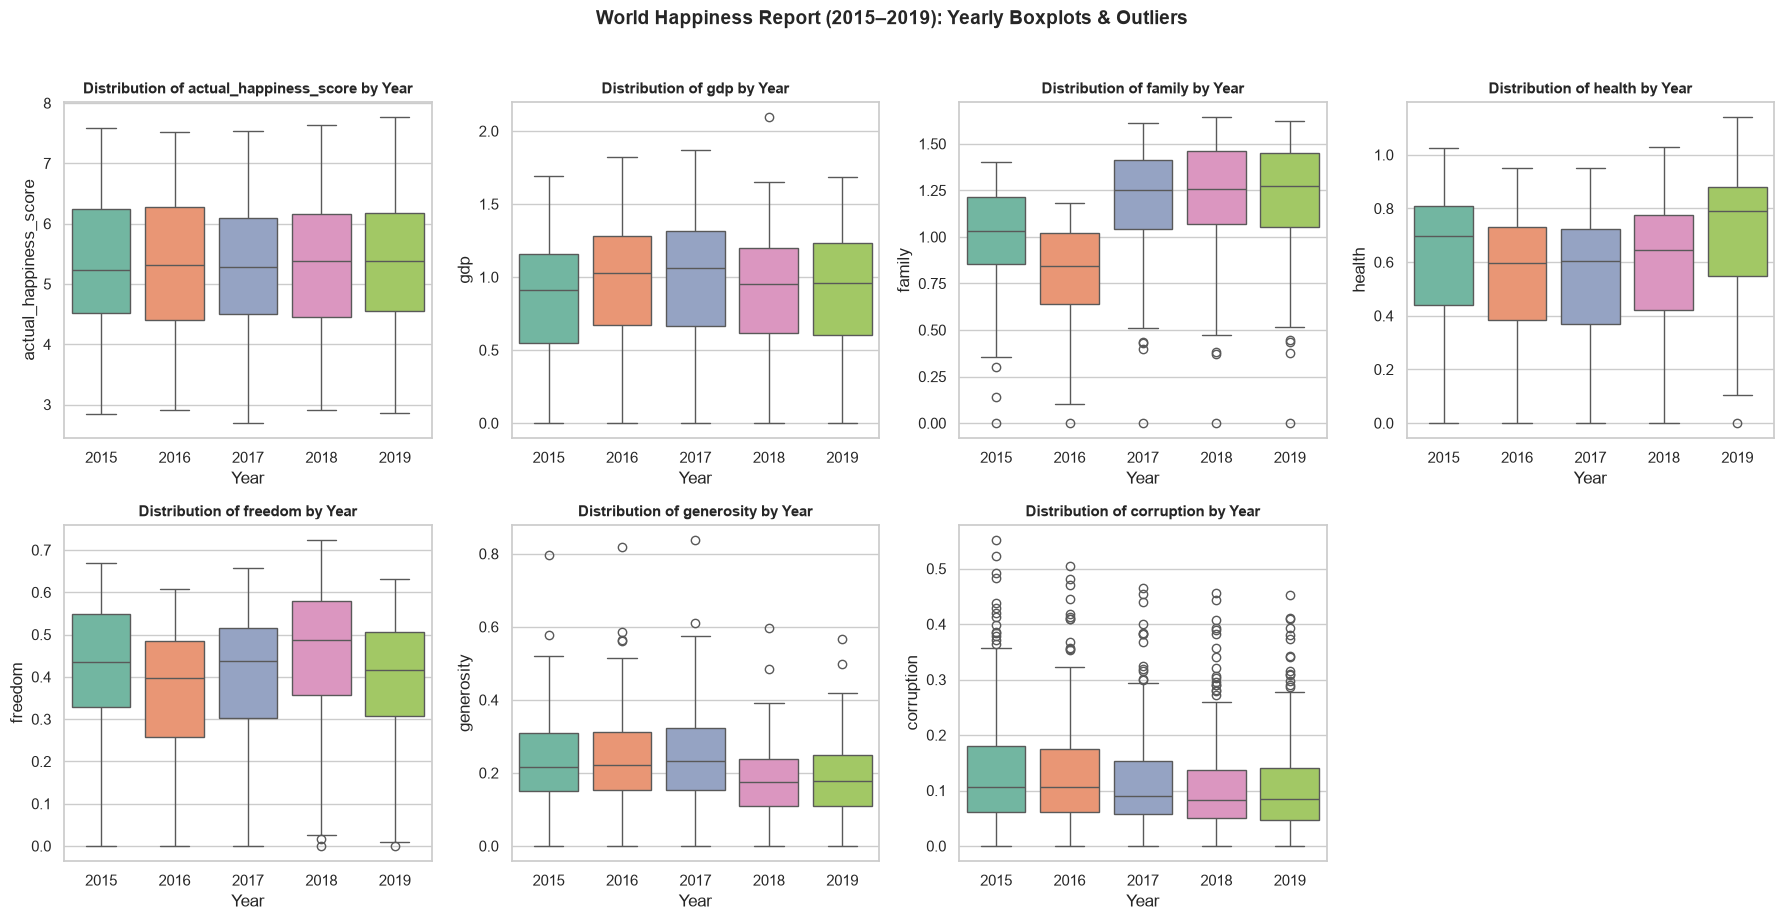

In [13]:
# Visualize Boxplots across the 5 years for all core numerical variables
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for idx, col in enumerate(NUMERIC_COLS):
    sns.boxplot(
        data=eda_combined,
        x="year",
        y=col,
        hue="year",
        palette="Set2",
        legend=False,
        ax=axes[idx]
    )
    axes[idx].set_title(f"Distribution of {col} by Year", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Year")
    axes[idx].set_ylabel(col)

# Hide unused 8th subplot
axes[7].axis("off")
plt.suptitle("World Happiness Report (2015–2019): Yearly Boxplots & Outliers", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

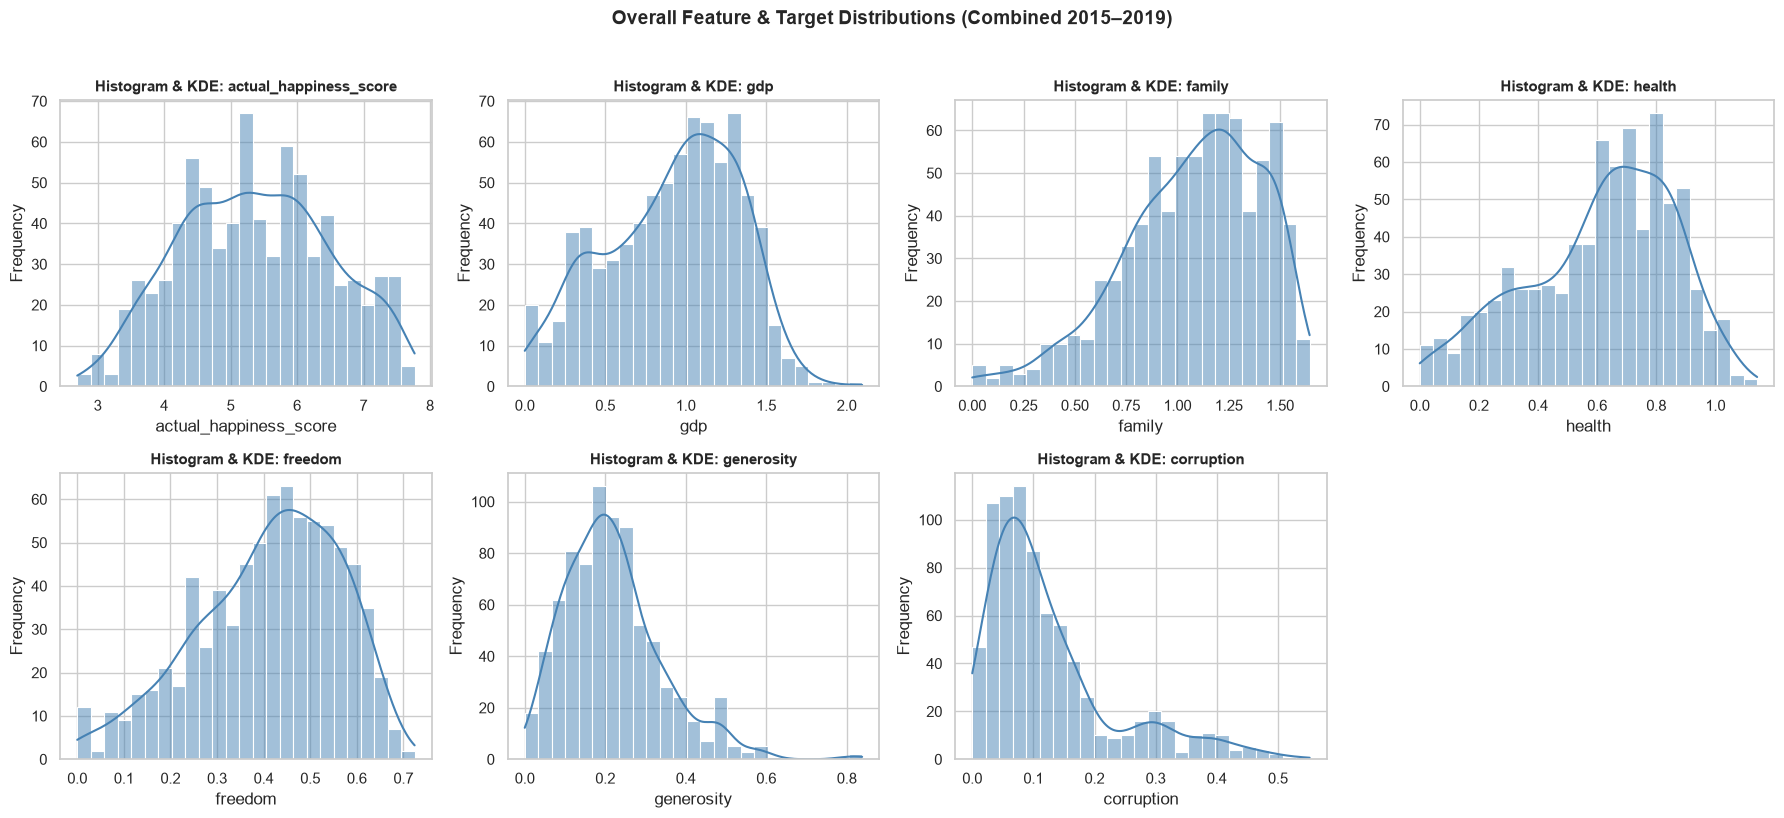

In [14]:
# Visualize Histograms + KDE to inspect skewness of each numerical variable
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for idx, col in enumerate(NUMERIC_COLS):
    sns.histplot(eda_combined[col].dropna(), kde=True, bins=25, color="steelblue", ax=axes[idx])
    axes[idx].set_title(f"Histogram & KDE: {col}", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Frequency")

axes[7].axis("off")
plt.suptitle("Overall Feature & Target Distributions (Combined 2015–2019)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## 7. Data Quality Observations & Unified Analytical Schema Proposal

### 7.1 Written Data Quality Observations
1. **Schema Drift & Column Naming Inconsistencies**:
   - Across `2015.csv`–`2019.csv`, column counts vary between **12 columns** (2015, 2017), **13 columns** (2016), and **9 columns** (2018, 2019).
   - **2015 & 2016** use human-readable names with parentheses (`Economy (GDP per Capita)`, `Health (Life Expectancy)`, `Trust (Government Corruption)`).
   - **2017** uses R-style dot-delimited identifiers (`Happiness.Rank`, `Happiness.Score`, `Economy..GDP.per.Capita.`, `Health..Life.Expectancy.`, `Trust..Government.Corruption.`).
   - **2018 & 2019** rename almost all columns (`Country or region`, `Overall rank`, `Score`, `GDP per capita`, `Social support`, `Healthy life expectancy`, `Freedom to make life choices`, `Perceptions of corruption`).
   - Auxiliary columns such as `Region` (only in 2015–2016), confidence intervals (`Standard Error`, `Lower/Upper Confidence Interval`, `Whisker.high/low` in 2015–2017), and `Dystopia Residual` (only in 2015–2017) are **not present in 2018–2019**. Furthermore, `Dystopia Residual` is derived directly from the target score minus the 6 factors, so including it would introduce severe **target leakage**.

2. **Missing Values**:
   - Out of **782 total rows** across all 5 files, there is **only 1 missing value** (`NaN`): in `2018.csv`, row index 19 (`United Arab Emirates`, `Overall rank = 20`) has `Perceptions of corruption = NaN`.
   - Because `United Arab Emirates` has valid corruption perception observations in 2015 (`0.38583`), 2016 (`0.35561`), 2017 (`0.32449`), and 2019 (`0.18200`), imputing this single value using the country-specific historical median/mean (or overall median) preserves the observation without losing an entire country-year record.

3. **Duplicated Records & Entity Naming Variations**:
   - There are **0 exact full-row duplicates** and **0 duplicate countries within any single year**.
   - However, **6 countries/territories change their string representation across years**:
     - `Hong Kong S.A.R., China` (2017) $\rightarrow$ `Hong Kong`
     - `Taiwan Province of China` (2017) $\rightarrow$ `Taiwan`
     - `Trinidad & Tobago` (2018–2019) $\rightarrow$ `Trinidad and Tobago`
     - `Northern Cyprus` (2018–2019) $\rightarrow$ `North Cyprus`
     - `North Macedonia` (2019) $\rightarrow$ `Macedonia`
     - `Somaliland Region` (2016) $\rightarrow$ `Somaliland region`
   - Normalizing these names reduces unique country strings from **170 to 164** and ensures consistent partitioning in Kafka (`country` key) and clean foreign keys in `dim_country`.

4. **Data Types**:
   - All numerical columns are properly parsed as `float64` (and rank as `int64`), and country names as `object`/`str`.
   - Floating-point precision varies by year (2017 stores 14 decimal places, whereas 2018–2019 store 3 decimal places), which is normal for `float64` operations.

5. **Outliers & Zero-Value Baselines**:
   - **Exact Zero Values (`0.0`)**: Each of the 6 explanatory factors (`gdp`, `family`, `health`, `freedom`, `generosity`, `corruption`) contains 5 to 6 exact `0.0` values across the 5 years (1 country per year). In the World Happiness Report methodology, each factor represents the *additional score contribution above Dystopia* (the minimum benchmark country in that year). Therefore, the lowest-scoring country on a factor in a given year legitimately receives `0.0`. These are **not** missing values.
   - **IQR Outliers**:
     - `actual_happiness_score`, `gdp`, `health`, and `freedom` exhibit **0 IQR outliers** and well-behaved distributions.
     - `family` has **10 lower-tail outliers** (e.g., Central African Republic, Togo, Syria during conflict years).
     - `generosity` (**17 upper-tail outliers**, e.g., Myanmar, Indonesia) and `corruption` (**67 upper-tail outliers**, e.g., Rwanda, Singapore, Nordic nations) are naturally **right-skewed** real-world socioeconomic distributions. Because they represent genuine country characteristics rather than measurement errors, they **must be retained** so the regression model can accurately predict across the full global spectrum.

---

### 7.2 Unified Analytical Schema Proposal
To harmonize all 5 historical datasets for **Part A (Machine Learning)** and ensure 100% compatibility with the **Part B (Apache Kafka Event Contract)**, we propose the following canonical **Unified Analytical Schema** (9 core columns):

| Unified Column Name | Data Type | Role in Pipeline | Source Mapping (`2015`–`2016` / `2017` / `2018`–`2019`) | Validation / Constraints |
| :--- | :--- | :--- | :--- | :--- |
| `country` | `string` | Entity Identifier & **Kafka Event Key** (`dim_country`) | `Country` / `Country` / `Country or region` | Non-empty string; standardized country name |
| `year` | `int64` | Temporal Dimension (`dim_date`) | Extracted from filename (`2015`..`2019`) | Integer in `[2015, 2019]` |
| `gdp` | `float64` | **ML Feature 1** (Economic production) | `Economy (GDP per Capita)` / `Economy..GDP.per.Capita.` / `GDP per capita` | Finite numeric (`>= 0.0`, no `NaN`) |
| `family` | `float64` | **ML Feature 2** (Social support) | `Family` / `Family` / `Social support` | Finite numeric (`>= 0.0`, no `NaN`) |
| `health` | `float64` | **ML Feature 3** (Life expectancy) | `Health (Life Expectancy)` / `Health..Life.Expectancy.` / `Healthy life expectancy` | Finite numeric (`>= 0.0`, no `NaN`) |
| `freedom` | `float64` | **ML Feature 4** (Life choices) | `Freedom` / `Freedom` / `Freedom to make life choices` | Finite numeric (`>= 0.0`, no `NaN`) |
| `generosity` | `float64` | **ML Feature 5** (Charitable giving) | `Generosity` / `Generosity` / `Generosity` | Finite numeric (`>= 0.0`, no `NaN`) |
| `corruption` | `float64` | **ML Feature 6** (Absence of corruption) | `Trust (Government Corruption)` / `Trust..Government.Corruption.` / `Perceptions of corruption` | Finite numeric (`>= 0.0`, no `NaN`) |
| `actual_happiness_score` | `float64` | **Target Variable ($y$)** (Offline training & online error evaluation) | `Happiness Score` / `Happiness.Score` / `Score` | Finite numeric (`> 0.0`, **never** used as input feature during inference) |

> **Why exclude `Happiness Rank`, `Region`, Confidence Intervals, and `Dystopia Residual`?**
> - `Region`, Confidence Intervals, and `Dystopia Residual` are absent in 2018–2019.
> - `Happiness Rank` is a direct ordinal ranking of `actual_happiness_score` and `Dystopia Residual` contains the unmodeled residual of `actual_happiness_score`; including either would cause severe **target leakage**.
> - This 9-column unified schema maps 1-to-1 to the Kafka JSON payload (`event_id` and `event_time` are added dynamically at streaming emission time in Part B).

---
# Part A — Step 2: Data Cleaning and Harmonization

### Objective
Translate the analytical findings and unified schema proposal from **Step 1** into a production-grade data cleaning and harmonization pipeline:
1. **Standardize Column Names & Schemas**: Apply year-specific mappings to reconcile naming variations into canonical names.
2. **Resolve Entity Naming Inconsistencies**: Standardize the 6 country name variations to ensure 100% consistency for Kafka event key partitioning and database dimension storage.
3. **Handle Missing Values**: Impute the single missing value (`Perceptions of corruption` for UAE in 2018) using historical country-specific median, fully justified.
4. **Standardize Data Types**: Enforce explicit data types (`int64` for year, `string` for country, `float64` for numerical factors and target).
5. **Merge Datasets into a Unified Master Dataset**: Concatenate all 5 years into a clean, unfragmented dataset of 782 records.
6. **Export Canonical Datasets**: Persist outputs to `../data/processed/` (for offline ML training) and `../data/streaming/` (for Kafka producer replay).

In [15]:
# 1. Define explicit column mappings and country name normalization rules
COLUMN_MAPPINGS = {
    2015: {
        "Country": "country",
        "Happiness Score": "actual_happiness_score",
        "Economy (GDP per Capita)": "gdp",
        "Family": "family",
        "Health (Life Expectancy)": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption"
    },
    2016: {
        "Country": "country",
        "Happiness Score": "actual_happiness_score",
        "Economy (GDP per Capita)": "gdp",
        "Family": "family",
        "Health (Life Expectancy)": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption"
    },
    2017: {
        "Country": "country",
        "Happiness.Score": "actual_happiness_score",
        "Economy..GDP.per.Capita.": "gdp",
        "Family": "family",
        "Health..Life.Expectancy.": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust..Government.Corruption.": "corruption"
    },
    2018: {
        "Country or region": "country",
        "Score": "actual_happiness_score",
        "GDP per capita": "gdp",
        "Social support": "family",
        "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption"
    },
    2019: {
        "Country or region": "country",
        "Score": "actual_happiness_score",
        "GDP per capita": "gdp",
        "Social support": "family",
        "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption"
    }
}

COUNTRY_NORMALIZATION_MAP = {
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Northern Cyprus": "North Cyprus",
    "North Macedonia": "Macedonia",
    "Somaliland Region": "Somaliland region"
}

CANONICAL_COLUMNS = [
    "country",
    "year",
    "gdp",
    "family",
    "health",
    "freedom",
    "generosity",
    "corruption",
    "actual_happiness_score"
]
print("Harmonization configurations defined successfully.")

Harmonization configurations defined successfully.


### 2. Imputation of Missing Value (United Arab Emirates, 2018)
In Step 1, we found that UAE in 2018 has `Perceptions of corruption = NaN`.
Rather than dropping this row and losing an entire nation's ranking in 2018, we calculate the **historical median** of UAE's corruption metric across all other available years (`2015`, `2016`, `2017`, `2019`) and impute it.

In [16]:
# Extract historical corruption values for United Arab Emirates
uae_historical_corruption = []
for yr in [2015, 2016, 2017, 2019]:
    df_yr = raw_datasets[yr]
    c_col = "Country" if "Country" in df_yr.columns else "Country or region"
    corr_col = [c for c in df_yr.columns if "Corruption" in c or "corruption" in c][0]
    val = df_yr.loc[df_yr[c_col] == "United Arab Emirates", corr_col].values[0]
    uae_historical_corruption.append(val)

uae_imputed_corruption = float(np.median(uae_historical_corruption))
print(f"UAE Historical corruption values: {uae_historical_corruption}")
print(f"Calculated historical median for imputation: {uae_imputed_corruption:.5f}")

UAE Historical corruption values: [np.float64(0.38583), np.float64(0.35561), np.float64(0.324489563703537), np.float64(0.182)]
Calculated historical median for imputation: 0.34005


### 3. Apply Harmonization, Imputation, and Merging Across All 5 Years

In [17]:
cleaned_dfs = []

for year in YEARS:
    # 1. Start with copy of raw dataset
    df_raw = raw_datasets[year].copy()
    
    # 2. Rename columns to canonical names
    df_mapped = df_raw.rename(columns=COLUMN_MAPPINGS[year])
    
    # 3. Add temporal identifier
    df_mapped["year"] = int(year)
    
    # 4. Clean country strings (strip whitespace & apply entity normalization)
    df_mapped["country"] = df_mapped["country"].astype(str).str.strip().replace(COUNTRY_NORMALIZATION_MAP)
    
    # 5. Handle missing value if present in this year
    if year == 2018:
        is_uae = df_mapped["country"] == "United Arab Emirates"
        if df_mapped.loc[is_uae, "corruption"].isna().any():
            df_mapped.loc[is_uae, "corruption"] = df_mapped.loc[is_uae, "corruption"].fillna(uae_imputed_corruption)
            print("Successfully imputed 2018 UAE corruption value.")
            
    # 6. Select only canonical columns in standardized order
    df_canonical = df_mapped[CANONICAL_COLUMNS].copy()
    
    # 7. Enforce strict data types
    df_canonical["country"] = df_canonical["country"].astype(str)
    df_canonical["year"] = df_canonical["year"].astype("int64")
    for num_col in ["gdp", "family", "health", "freedom", "generosity", "corruption", "actual_happiness_score"]:
        df_canonical[num_col] = df_canonical[num_col].astype("float64")
        
    cleaned_dfs.append(df_canonical)

# Concatenate into unified dataset
unified_df = pd.concat(cleaned_dfs, ignore_index=True)
print(f"Unified dataset constructed. Shape: {unified_df.shape}")
display(unified_df.head(5))

Successfully imputed 2018 UAE corruption value.
Unified dataset constructed. Shape: (782, 9)


,country,year,gdp,family,health,freedom,generosity,corruption,actual_happiness_score
0,Switzerland,2015,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,7.587
1,Iceland,2015,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,7.561
2,Denmark,2015,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,7.527
3,Norway,2015,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,7.522
4,Canada,2015,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,7.427


### 4. Post-Harmonization Quality Validation
Verify that the unified dataset strictly satisfies all quality requirements:
- No missing values anywhere.
- No duplicate records (neither full-row nor `(country, year)` entity-level).
- Correct row count (exactly 782 rows, matching the sum of raw files).
- Consistent schema matching the canonical definition.

In [18]:
# 4.1 Completeness and Shape Checks
assert unified_df.shape == (782, 9), f"Unexpected shape: {unified_df.shape}"
assert unified_df.isna().sum().sum() == 0, "Missing values detected in unified dataset!"
assert unified_df.duplicated().sum() == 0, "Duplicate rows detected!"
assert unified_df.duplicated(subset=["country", "year"]).sum() == 0, "Duplicate (country, year) combinations detected!"

validation_summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Total Missing Values",
        "Full-Row Duplicates",
        "Unique Countries",
        "Years Covered",
        "Min Happiness Score",
        "Max Happiness Score"
    ],
    "Value": [
        len(unified_df),
        len(unified_df.columns),
        int(unified_df.isna().sum().sum()),
        int(unified_df.duplicated().sum()),
        unified_df["country"].nunique(),
        f"{unified_df['year'].min()} – {unified_df['year'].max()}",
        round(unified_df["actual_happiness_score"].min(), 4),
        round(unified_df["actual_happiness_score"].max(), 4)
    ]
})

print("All assertion checks PASSED.")
display(validation_summary)

All assertion checks PASSED.


,Metric,Value
0,Total Rows,782
1,Total Columns,9
2,Total Missing Values,0
3,Full-Row Duplicates,0
4,Unique Countries,164
5,Years Covered,2015 – 2019
6,Min Happiness Score,2.693
7,Max Happiness Score,7.769


In [19]:
# 4.2 Display data types and sample summary statistics of the unified dataset
print("Data types:")
print(unified_df.dtypes)
print("\nDescriptive statistics:")
display(unified_df.describe().round(4))

Data types:
country                       str
year                        int64
gdp                       float64
family                    float64
health                    float64
freedom                   float64
generosity                float64
corruption                float64
actual_happiness_score    float64
dtype: object

Descriptive statistics:


,year,gdp,family,health,freedom,generosity,corruption,actual_happiness_score
count,782.0000,782.0000,782.0000,782.0000,782.0000,782.0000,782.0000,782.0000
mean,2016.9936,0.9160,1.0784,0.6124,0.4111,0.2186,0.1257,5.3790
std,1.4174,0.4073,0.3295,0.2483,0.1529,0.1223,0.1060,1.1275
min,2015.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.6930
25%,2016.0000,0.6065,0.8694,0.4402,0.3098,0.1300,0.0542,4.5098
50%,2017.0000,0.9822,1.1247,0.6473,0.4310,0.2020,0.0910,5.3220
75%,2018.0000,1.2362,1.3272,0.8080,0.5310,0.2788,0.1562,6.1895
max,2019.0000,2.0960,1.6440,1.1410,0.7240,0.8381,0.5519,7.7690


### 5. Export Unified Datasets
Export the clean, harmonized data to the required locations:
1. `../data/processed/happiness_cleaned.csv`: Cleaned historical dataset used for **Feature Engineering & ML Training** (Steps 3 & 4).
2. `../data/streaming/happiness_streaming.csv`: Source dataset from which the **Kafka Producer** (Step 5) will read records sequentially to simulate real-time streaming events.

In [20]:
PROCESSED_DATA_DIR = Path("../data/processed") if Path("../data/processed").exists() else Path("data/processed")
STREAMING_DATA_DIR = Path("../data/streaming") if Path("../data/streaming").exists() else Path("data/streaming")

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
STREAMING_DATA_DIR.mkdir(parents=True, exist_ok=True)

processed_file = PROCESSED_DATA_DIR / "happiness_cleaned.csv"
streaming_file = STREAMING_DATA_DIR / "happiness_streaming.csv"

# Export without index
unified_df.to_csv(processed_file, index=False)
unified_df.to_csv(streaming_file, index=False)

print(f"Exported clean offline dataset to : {processed_file.resolve()} ({processed_file.stat().st_size} bytes)")
print(f"Exported clean streaming dataset to: {streaming_file.resolve()} ({streaming_file.stat().st_size} bytes)")

Exported clean offline dataset to : C:\Users\juand\Desktop\mis_cosas\uao\etl\workshops\workshop-3\data\processed\happiness_cleaned.csv (60593 bytes)
Exported clean streaming dataset to: C:\Users\juand\Desktop\mis_cosas\uao\etl\workshops\workshop-3\data\streaming\happiness_streaming.csv (60593 bytes)


In [21]:
# Verify exported files can be reloaded cleanly
df_check_proc = pd.read_csv(processed_file)
df_check_strm = pd.read_csv(streaming_file)

assert df_check_proc.shape == (782, 9)
assert df_check_strm.shape == (782, 9)
print(f"Verification successful: Both files reloaded cleanly with shape {df_check_proc.shape}.")

Verification successful: Both files reloaded cleanly with shape (782, 9).
